Data handling library

In [2]:
import pandas as pd
import numpy as np


Data loading

In [3]:
aisles = pd.read_csv('aisles.csv')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
departments = pd.read_csv('departments.csv')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
orders = pd.read_csv('orders.csv')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
order_products__prior = pd.read_csv('order_products__prior.csv')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
products = pd.read_csv('products.csv')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')


Data understanding

In [4]:
print('aisles.info()')
aisles.info()
print('\ndepartments.info()')
departments.info()
print('\norders.info()')
orders.info()
print('\nproducts.info()')
products.info()
print('\norder_products__prior.info()')
order_products__prior.info()


aisles.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB

departments.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes

orders.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                object 
 3   order_number  

In [5]:
print('aisles.describe()')
print(aisles.describe())
print('\ndepartments.describe()')
print(departments.describe())
print('\norders.describe()')
print(orders.describe())
print('\nproducts.describe()')
print(products.describe())
print('\norder_products__prior.describe()')
print(order_products__prior.describe())

aisles.describe()
       aisle_id
count   134.000
mean     67.500
std      38.827
min       1.000
25%      34.250
50%      67.500
75%     100.750
max     134.000

departments.describe()
       department_id
count         21.000
mean          11.000
std            6.205
min            1.000
25%            6.000
50%           11.000
75%           16.000
max           21.000

orders.describe()
           order_id       user_id  order_number     order_dow  \
count 3,421,083.000 3,421,083.000 3,421,083.000 3,421,083.000   
mean  1,710,542.000   102,978.208        17.155         2.776   
std     987,581.740    59,533.718        17.733         2.047   
min           1.000         1.000         1.000         0.000   
25%     855,271.500    51,394.000         5.000         1.000   
50%   1,710,542.000   102,689.000        11.000         3.000   
75%   2,565,812.500   154,385.000        23.000         5.000   
max   3,421,083.000   206,209.000       100.000         6.000   

       order_hour_of

In [6]:
print('aisles.value_counts(),134')
print(aisles.value_counts())
print('\ndepartments.value_counts(),21')
print(departments.value_counts())
print('\norders.value_counts(),3421083')
print(orders.value_counts())
print('\nproducts.value_counts(),49688')
print(products.value_counts())
print('\norder_products__prior.value_counts(), 32434489')
print(order_products__prior.value_counts())

aisles.value_counts(),134
aisle_id  aisle                     
1         prepared soups salads         1
2         specialty cheeses             1
3         energy granola bars           1
4         instant foods                 1
5         marinades meat preparation    1
                                       ..
130       hot cereal pancake mixes      1
131       dry pasta                     1
132       beauty                        1
133       muscles joints pain relief    1
134       specialty wines champagnes    1
Name: count, Length: 134, dtype: int64

departments.value_counts(),21
department_id  department     
1              frozen             1
2              other              1
3              bakery             1
4              produce            1
5              alcohol            1
6              international      1
7              beverages          1
8              pets               1
9              dry goods pasta    1
10             bulk               1
11            

Data Cleaning

Step 1 Check for blank columns

In [40]:
aisles_blank_columns = aisles.columns[aisles.isna().all()].tolist()
print('aisles_blank_columns', aisles_blank_columns)
departments_blank_columns = departments.columns[departments.isna().all()].tolist()
print('departments_blank_columns', departments_blank_columns)
orders_blank_columns = orders.columns[orders.isna().all()].tolist()
print('orders_blank_columns', orders_blank_columns)
products_blank_columns = products.columns[products.isna().all()].tolist()
print('products_blank_columns', products_blank_columns)
order_products__prior_blank_columns = order_products__prior.columns[order_products__prior.isna().all()].tolist()
print('order_products__prior_blank_columns', order_products__prior_blank_columns)

aisles_blank_columns []
departments_blank_columns []
orders_blank_columns []
products_blank_columns []
order_products__prior_blank_columns []


Step 2 Check for column with blank row

In [7]:
print('aisles.isna().any():\n', aisles.isna().any())
print('\ndepartments.isna().any():\n', departments.isna().any())
print('\norders.isna().any():\n', orders.isna().any())
print('\nproducts.isna().any():\n', products.isna().any())
print('\norder_products__prior.isna().any():\n', order_products__prior.isna().any())

aisles.isna().any():
 aisle_id    False
aisle       False
dtype: bool

departments.isna().any():
 department_id    False
department       False
dtype: bool

orders.isna().any():
 order_id                  False
user_id                   False
eval_set                  False
order_number              False
order_dow                 False
order_hour_of_day         False
days_since_prior_order     True
dtype: bool

products.isna().any():
 product_id       False
product_name     False
aisle_id         False
department_id    False
dtype: bool

order_products__prior.isna().any():
 order_id             False
product_id           False
add_to_cart_order    False
reordered            False
dtype: bool


Step 3 Check for duplicates

In [8]:
print("duplicates in aisles:", aisles.duplicated().sum())
print("duplicates in departments:", departments.duplicated().sum())
print("duplicates in orders:", orders.duplicated().sum())
print("duplicates in products:", products.duplicated().sum())
print("duplicates in order_products__prior:", order_products__prior.duplicated().sum())

duplicates in aisles: 0
duplicates in departments: 0
duplicates in orders: 0
duplicates in products: 0
duplicates in order_products__prior: 0


Step 4 Check for percentage of blank rows in orders

In [11]:
orders.isna().sum()

order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Step 5 Check orders for a relation between null values and other parameters

In [10]:
orders.nunique()

order_id                  3421083
user_id                    206209
eval_set                        3
order_number                  100
order_dow                       7
order_hour_of_day              24
days_since_prior_order         31
dtype: int64

         The above result shows that the blank in 'days_since_prior_order' are first time order user.

Step 6 Check for "missing"

In [45]:
print((aisles == "missing").sum(),"\n")
print((departments == "missing").sum(),"\n")
print((orders == "missing").sum(),"\n")
print((products == "missing").sum(),"\n")
print((order_products__prior == "missing").sum(),"\n")

aisle_id    0
aisle       1
dtype: int64 

department_id    0
department       1
dtype: int64 

order_id                  0
user_id                   0
eval_set                  0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64 

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64 

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64 



Orders amount vs Number of Product per Order \
This is to understand for maximum orders, there are mostly how many products. \
The graph below show that for maximum orders, there are 5 to 6 products.

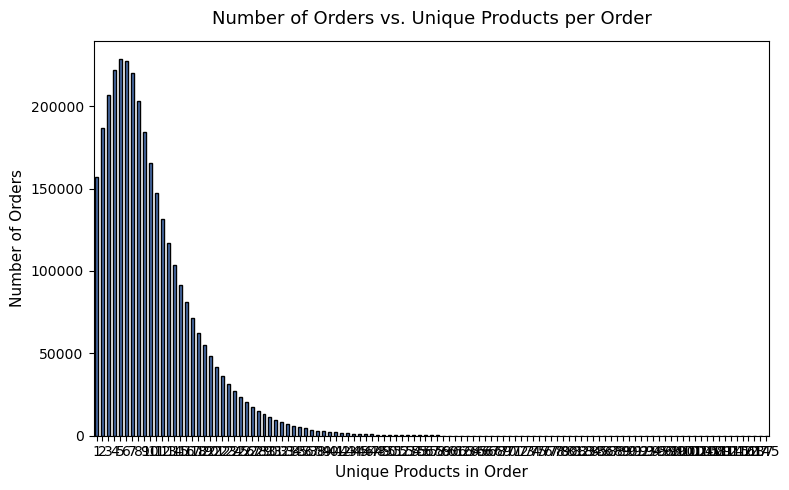

In [17]:
import matplotlib.pyplot as plt

df = order_products__prior

# Calculate unique products per order, then count orders per basket size
order_counts = (
    df.groupby('order_id')['product_id']
    .nunique()
    .value_counts()
    .sort_index()
)

# Plot the bar chart
ax = order_counts.plot.bar(
    figsize=(8, 5),
    color='#4C72B0',
    edgecolor='black',
    rot=0  # Keeps x-axis numbers horizontal
)

# 3. Add labels, title, and bar value annotations
ax.set_title('Number of Orders vs. Unique Products per Order', fontsize=13, pad=12)
ax.set_xlabel('Unique Products in Order', fontsize=11)
ax.set_ylabel('Number of Orders', fontsize=11)
#ax.bar_label(ax.containers[0], padding=3)  # Displays exact order count above each bar

plt.tight_layout()
plt.show()

Orders amount vs day of week

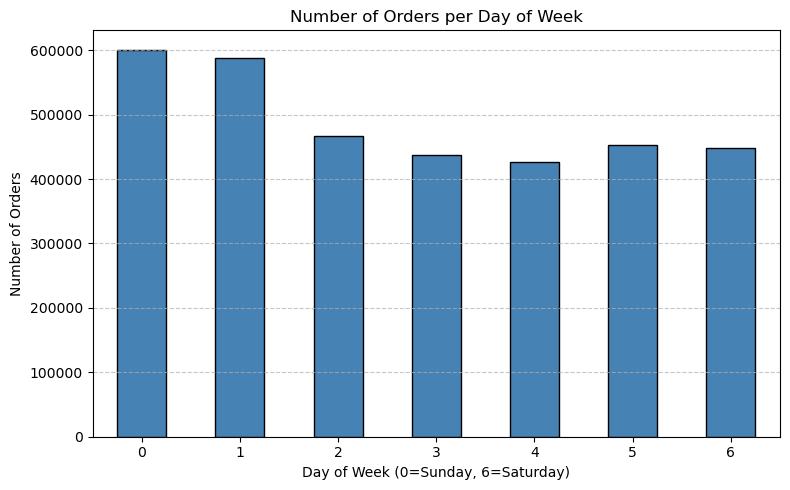

In [19]:
df = orders

# Count unique order_ids per day_of_week (0 to 6)
orders_per_day = (
    df.groupby('order_dow')['order_id']
    .nunique()
    .reindex(range(7), fill_value=0)
)

# bar chart
plt.figure(figsize=(8, 5))
orders_per_day.plot(kind='bar', color='steelblue', edgecolor='black')

plt.title('Number of Orders per Day of Week')
plt.xlabel('Day of Week (0=Sunday, 6=Saturday)')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)  # Keep x-axis numbers upright
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Top 10 selling products

In [29]:
# Count frequency of each product_id
top_products = (
    order_products__prior['product_id']
    .value_counts()
    .reset_index(name='frequency')
)

# Merge to bring in product_name

top_products = pd.merge(
    top_products,
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

# Reorder columns for readability
top_products = top_products[['product_id', 'product_name', 'frequency']]

print(top_products.head(10))  # Display top 10 products by frequency




   product_id            product_name  frequency
0       24852                  Banana     472565
1       13176  Bag of Organic Bananas     379450
2       21137    Organic Strawberries     264683
3       21903    Organic Baby Spinach     241921
4       47209    Organic Hass Avocado     213584
5       47766         Organic Avocado     176815
6       47626             Large Lemon     152657
7       16797            Strawberries     142951
8       26209                   Limes     140627
9       27845      Organic Whole Milk     137905


Which specific products does each individual customer habitually reorder every 7 days? \
Filter by number of orders > 3

In [37]:
pd.set_option('display.width', 1000)

# 1. Filter orders where days_since_prior_order == 7
weekly_orders = orders[orders['days_since_prior_order'] == 7][
    ['order_id', 'user_id']
]

# 2. Filter order_products__prior where reordered == 1
reordered_prior = order_products__prior[order_products__prior['reordered'] == 1][
    ['order_id', 'product_id']
]

# 3. Inner merge them together
merged = pd.merge(reordered_prior, weekly_orders, on='order_id', how='inner')

# 4. Group by user_id and product_id, then count order_id
user_product_orders = (
    merged.groupby(['user_id', 'product_id'])['order_id']
    .count()
    .reset_index(name='No_of_orders')
)

# 5. Filter for No_of_orders >= 3 (equivalent to SQL HAVING)
habitual_orders = user_product_orders[user_product_orders['No_of_orders'] >= 3]

# 6. Merge with products for product_name and sort
result = pd.merge(
    habitual_orders,
    products[['product_id', 'product_name']],
    on='product_id',
    how='inner',
)[['user_id', 'product_id', 'product_name', 'No_of_orders']].sort_values(
    by=['user_id', 'No_of_orders'], ascending=[True, False]
)

print(result.head(10))

    user_id  product_id                     product_name  No_of_orders
0         3       39190  Vanilla Unsweetened Almond Milk             4
1         3       47766                  Organic Avocado             3
2        13        4210                       Whole Milk             4
3        13       27086                      Half & Half             4
4        15       14715                    Coconut Water             3
7        21       48988     Unsweetened Premium Iced Tea             4
5        21       23729                 Hard Boiled Eggs             3
6        21       43645                Eggs, Hard-Boiled             3
8        27        2966               Pure Coconut Water             4
10       27        9604    Hibiscus Organic Raw Kombucha             4
